# E-handel – Försäljningsanalys

## 1.Introduktion

Syftet med rapporten är att analysera försäljningsdata från en e-handelsplattform.

Vi ska undersöka:
- Vilka produktkategorier som ger störst intäkter.
- Vilka städer som har högst försäljning.
- Hur försäljningen förändras över tid.
- Genomsnittligt ordervärde (AOV).
- Topp 3 produktkategorier.
- Eventuella avvikelser i försäljningen.

Avslutningsvis presenterar vi rekommendationer inför nästa kampanjperiod.

## 2. Datainläsning

Vi läser in försäljningsdata från CSV-filen och kontrollerar att informationen har lästs in korrekt.

In [1]:
import pandas as pd
import sys
from pathlib import Path

# Lägg till gruppens src-mapp
projektmapp = Path.cwd().resolve()
if projektmapp.name == "notebooks":
    projektmapp = projektmapp.parent

sys.path.insert(0, str(projektmapp / "src"))

# Importera gruppens gemensamma kod
from io_utils import load_data
from ecommerce import EcommerceAnalyzer
import metrics
import viz

# Läs in försäljningsdata
df = load_data(projektmapp / "data" / "ecommerce_sales.csv")

# Skapa analysobjektet
if df is None:
    raise FileNotFoundError("Kunde inte läsa in försäljningsdata.")

analyzer = EcommerceAnalyzer(df)

print("Data har lästs in!")
print("Antal rader:", len(df))

# Visa de första fem raderna i en tabell
display(df.head())

Data har lästs in!
Antal rader: 2500


,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


## 3. Nyckeltal

Här sammanställer vi viktiga nyckeltal för e-handelns försäljning.

In [2]:
# Hämta försäljningsstatistik från gruppens gemensamma funktion
kategori_statistik = metrics.category_revenue_table(df)

# Sortera kategorierna efter högst försäljningsintäkt
kategori_statistik = kategori_statistik.sort_values(
    by="kronor", ascending=False
).reset_index(drop=True)

# Visa resultatet som en tydlig tabell
display(kategori_statistik.round(2))

,category,kronor,count,mean,median,std
0,Electronics,1364228.07,618,2207.49,1844.94,1531.68
1,Sports,734653.42,415,1770.25,1595.76,1080.91
2,Clothing,586744.91,509,1152.74,1016.24,765.74
3,Home,511070.87,490,1043.00,897.70,721.21
4,Beauty,163053.97,241,676.57,584.91,482.36
5,Toys,143015.99,227,630.03,533.98,468.67


### Gemensamma beräkningsfunktioner

Vi använder återanvändbara beräkningsfunktioner från gruppens gemensamma Python-fil `metrics.py`.

Funktionerna beräknar total försäljningsintäkt, totalt antal sålda enheter och genomsnittligt ordervärde (AOV).

Genom att samla funktionerna i en gemensam fil undviker vi upprepad kod och får en tydligare och mer lättunderhållen kodstruktur.

In [3]:
# Använd gruppens gemensamma funktioner från metrics.py

print("Total försäljningsintäkt:", round(metrics.revenue_sum(df), 2))
print("Totalt antal sålda enheter:", metrics.units_sum(df))
print("Genomsnittligt ordervärde (AOV):", round(metrics.aov(df), 2))


Total försäljningsintäkt: 3502767.23
Totalt antal sålda enheter: 7463
Genomsnittligt ordervärde (AOV): 1401.11


### Sammanfattning av nyckeltal

Vi har beräknat den totala försäljningsintäkten, totalt antal sålda enheter och genomsnittligt ordervärde (AOV).

Dessa nyckeltal ger en övergripande bild av e-handelns försäljning och hjälper ledningen att förstå försäljningens omfattning.

## 4. Försäljningsintäkt per produktkategori

Diagrammet visar hur försäljningsintäkterna fördelar sig mellan olika produktkategorier.

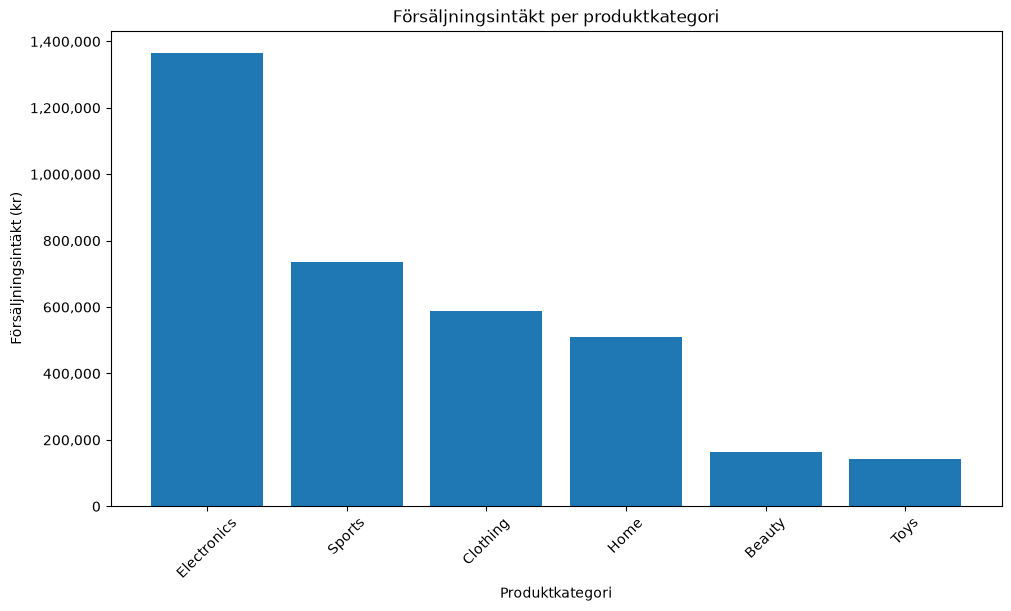

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Skapa diagram med gruppens gemensamma funktion
fig = viz.plot_revenue_by_category(df)

# Förtydliga diagrammets rubriker och axlar
ax = fig.axes[0]
ax.set_title("Försäljningsintäkt per produktkategori")
ax.set_xlabel("Produktkategori")
ax.set_ylabel("Försäljningsintäkt (kr)")

# Visa hela belopp på y-axeln
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Rotera kategorinamnen för bättre läsbarhet
ax.tick_params(axis="x", labelrotation=45)

plt.show()


### Analys

Electronics har högst försäljningsintäkt med cirka 1,36 miljoner kronor, följt av Sports med cirka 735 000 kronor och Clothing med cirka 587 000 kronor.

Beauty och Toys har de lägsta försäljningsintäkterna under den analyserade perioden.

Resultatet visar att försäljningen skiljer sig tydligt mellan produktkategorierna. Electronics är den största kategorin sett till intäkter och kan därför vara särskilt intressant att undersöka inför nästa kampanjperiod.

Det är dock viktigt att även analysera exempelvis försäljningsvolym och lönsamhet innan beslut fattas om vilka kategorier som ska prioriteras.

## 5. Försäljningsintäkt per stad

Vi undersöker vilka städer som genererar störst försäljningsintäkter för att identifiera viktiga geografiska marknader inför nästa kampanjperiod.

In [5]:
# Beräkna försäljningsstatistik per stad
stad_statistik = (
    df.groupby("city")["revenue"]
    .agg(
        kronor="sum",
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .reset_index()
    .rename(columns={"city": "stad"}))

# Sortera städerna efter högst försäljningsintäkt
stad_statistik = stad_statistik.sort_values(
    by="kronor", ascending=False
).reset_index(drop=True)

# Visa resultatet som en tydlig tabell
display(stad_statistik.round(2))

,stad,kronor,count,mean,median,std
0,Stockholm,1227201.94,899,1365.07,1080.39,1118.89
1,Göteborg,859019.65,586,1465.90,1146.32,1200.83
2,Malmö,567926.32,396,1434.16,1074.66,1186.51
3,Uppsala,551478.42,381,1447.45,1118.10,1248.01
4,Västerås,297140.90,238,1248.49,980.36,1080.89


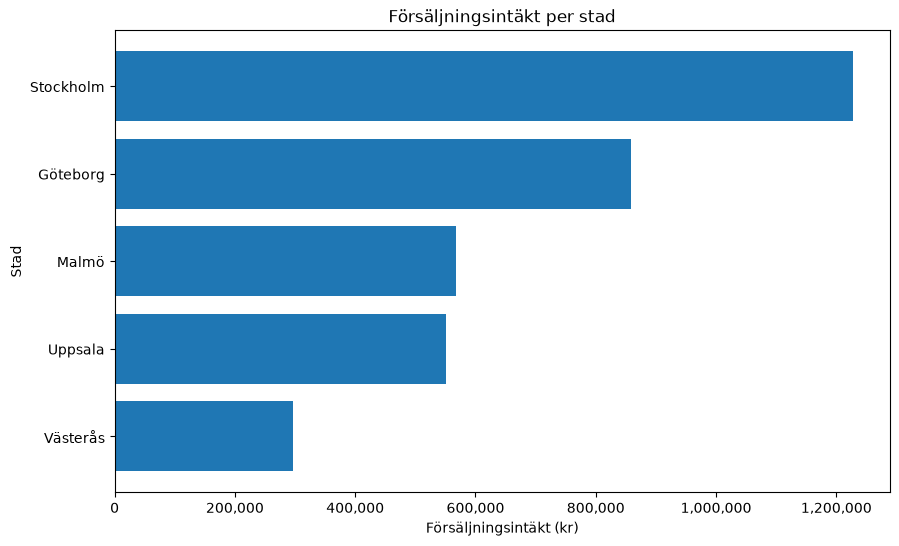

In [6]:
# Skapa diagram med gruppens gemensamma funktion
fig = viz.plot_revenue_by_city(df)

# Förbättra diagrammets utseende
from matplotlib.ticker import StrMethodFormatter

ax = fig.axes[0]
ax.set_title("Försäljningsintäkt per stad")
ax.set_xlabel("Försäljningsintäkt (kr)")
ax.set_ylabel("Stad")

# Visa hela belopp utan vetenskaplig notation
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

plt.show()

### Analys

Stockholm har högst försäljningsintäkt med cirka 1,23 miljoner kronor, följt av Göteborg med cirka 859 000 kronor och Malmö med cirka 568 000 kronor.

Västerås har den lägsta försäljningsintäkten med cirka 297 000 kronor.

Resultatet visar att försäljningsintäkterna skiljer sig mellan städerna. Stockholm och Göteborg står för en stor del av den totala försäljningen och kan därför vara särskilt intressanta att undersöka inför nästa kampanjperiod.

## 6. Försäljning över tid

Vi undersöker hur försäljningsintäkterna förändras mellan månaderna för att identifiera eventuella tidsmönster.

In [7]:
# Omvandla datum till datumformat
df["date"] = pd.to_datetime(df["date"])

# Skapa en kolumn med år och månad
df["month"] = df["date"].dt.to_period("M")

# Beräkna försäljningsintäkt per månad
intakt_manad = df.groupby("month")["revenue"].sum()

# Visa resultatet som en tydlig tabell
manad_tabell = intakt_manad.reset_index()
manad_tabell.columns = ["Månad", "Försäljningsintäkt (kr)"]

# Avrunda endast försäljningsintäkten till två decimaler
manad_tabell["Försäljningsintäkt (kr)"] = manad_tabell["Försäljningsintäkt (kr)"].round(2)

# Visa tabellen
display(manad_tabell)

,Månad,Försäljningsintäkt (kr)
0,2024-01,664083.32
1,2024-02,548462.03
2,2024-03,487602.00
3,2024-04,580194.83
4,2024-05,632165.16
5,2024-06,590259.89


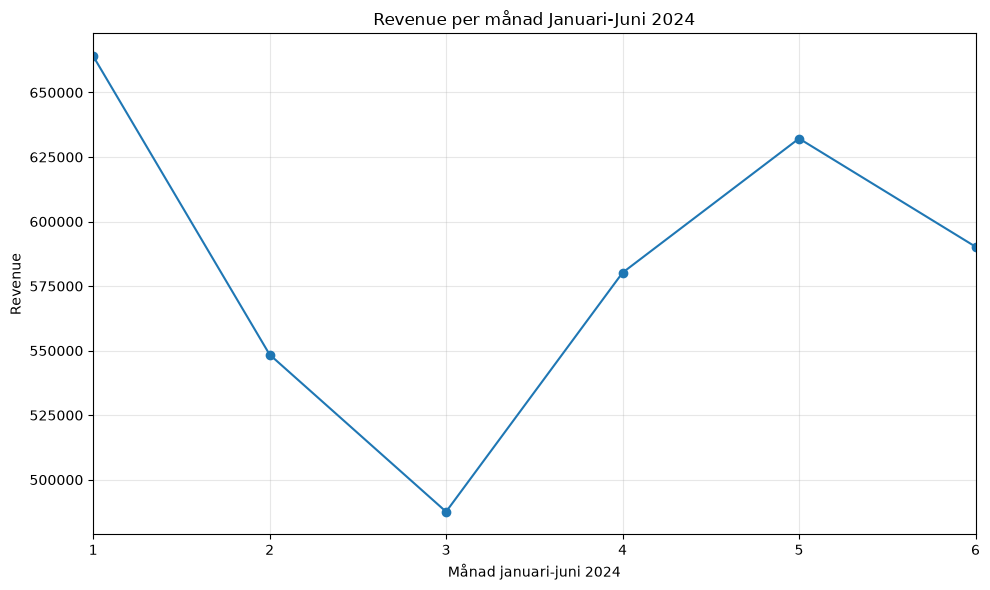

In [8]:
# Skapa diagram med gruppens gemensamma funktion
viz.plot_revenue_over_time(df, period="month")

### Analys – Försäljning över tid

Diagrammet visar hur försäljningsintäkterna varierade mellan januari och juni 2024.

- **Januari** hade högst försäljningsintäkt med **664 083,32 kr**.
- **Mars** hade lägst försäljningsintäkt med **487 602,00 kr**.
- Efter nedgången mellan januari och mars ökade försäljningen under april och maj.
- I juni minskade försäljningsintäkterna något jämfört med maj.

Resultatet visar att försäljningen varierar mellan månaderna. Dessa skillnader kan vara relevanta inför planeringen av kommande kampanjer. För att avgöra om variationerna beror på säsongsmönster behövs dock försäljningsdata från fler perioder.

## 7. Topp 3 produktkategorier

Vi identifierar de tre produktkategorier som genererar högst försäljningsintäkter.

In [9]:
# Hämta de tre produktkategorierna med högst intäkt
topp_3 = metrics.top_category_revenue(df)

# Skapa en tydlig tabell med placering 1, 2 och 3
topp_3_tabell = topp_3[["category", "kronor"]].reset_index(drop=True)

# Lägg till placering som en vanlig kolumn
topp_3_tabell.insert(0, "Placering", range(1, len(topp_3_tabell) + 1))

# Ge kolumnerna svenska rubriker
topp_3_tabell = topp_3_tabell.rename(columns={
    "category": "Produktkategori",
    "kronor": "Försäljningsintäkt (kr)"})

# Visa tabellen utan extra indexkolumn
print(topp_3_tabell.round(2).to_string(index=False))

 Placering Produktkategori  Försäljningsintäkt (kr)
         1     Electronics               1364228.07
         2          Sports                734653.42
         3        Clothing                586744.91


### Analys

Electronics är den mest intäktsgenererande kategorin, följt av Sports och Clothing.

Dessa tre kategorier kan vara särskilt intressanta att analysera inför nästa kampanjperiod.

## 8. Genomsnittligt ordervärde (AOV) och spridning

Vi undersöker hur mycket kunderna i genomsnitt handlar för per order och hur ordervärdena varierar.

AOV (Average Order Value) beräknas genom att dividera den totala försäljningsintäkten med antalet unika ordrar.

In [10]:
# Beräkna ordervärdet för varje unik order
order_intakter = df.groupby("order_id")["revenue"].sum()

# Använd gruppens gemensamma funktion för AOV
aov = metrics.aov(df)

# Beräkna spridningen mellan ordervärdena
median = order_intakter.median()
minsta = order_intakter.min()
hogsta = order_intakter.max()
standardavvikelse = order_intakter.std()

# Visa resultaten
print("Genomsnittligt ordervärde (AOV):", round(aov, 2))
print("Median:", round(median, 2))
print("Lägsta ordervärde:", round(minsta, 2))
print("Högsta ordervärde:", round(hogsta, 2))
print("Standardavvikelse:", round(standardavvikelse, 2))

Genomsnittligt ordervärde (AOV): 1401.11
Median: 1088.69
Lägsta ordervärde: 50.0
Högsta ordervärde: 9192.6
Standardavvikelse: 1166.94



### Analys

Det genomsnittliga ordervärdet (AOV) är **1 401,11 kr**, medan medianen är **1 088,69 kr**. Att medelvärdet är högre än medianen tyder på att vissa större beställningar höjer genomsnittet.

Det lägsta ordervärdet är **50,00 kr** och det högsta är **9 192,60 kr**. Standardavvikelsen är **1 166,94 kr**, vilket visar att ordervärdena har en relativt stor spridning.

Resultatet visar att kundernas beställningar varierar betydligt i värde. Detta kan vara relevant för att förstå kundernas köpbeteende och planera framtida kampanjer. För att dra säkrare slutsatser behöver även fördelningen av ordervärden undersökas närmare.


## 9. Avvikelser och observationer

Vi undersöker om det finns några tydliga skillnader eller oväntade mönster i försäljningsstatistiken.

Analysen utgår från försäljningsintäkter per produktkategori, stad och månad samt variationer i ordervärden.

In [11]:
# Hämta kategoriernas försäljningsstatistik
kategori_statistik = metrics.category_revenue_table(df)

# Identifiera högsta och lägsta intäkt per kategori
hogsta_kategori = kategori_statistik.loc[kategori_statistik["kronor"].idxmax()]
lagsta_kategori = kategori_statistik.loc[kategori_statistik["kronor"].idxmin()]

print("Kategori med högst intäkt:")
print(hogsta_kategori["category"], round(hogsta_kategori["kronor"], 2))

print("\nKategori med lägst intäkt:")
print(lagsta_kategori["category"], round(lagsta_kategori["kronor"], 2))

# Identifiera högsta och lägsta intäkt per månad
print("\nMånad med högst intäkt:")
print(intakt_manad.idxmax(), round(intakt_manad.max(), 2))

print("\nMånad med lägst intäkt:")
print(intakt_manad.idxmin(), round(intakt_manad.min(), 2))

# Undersök variationen i ordervärden
print("\nLägsta ordervärde:", round(order_intakter.min(), 2))
print("Högsta ordervärde:", round(order_intakter.max(), 2))

Kategori med högst intäkt:
Electronics 1364228.07

Kategori med lägst intäkt:
Toys 143015.99

Månad med högst intäkt:
2024-01 664083.32

Månad med lägst intäkt:
2024-03 487602.0

Lägsta ordervärde: 50.0
Högsta ordervärde: 9192.6


### Analys

Försäljningsstatistiken visar några tydliga skillnader:

- **Produktkategorier:** Electronics har högst försäljningsintäkt, medan Toys har lägst.
- **Försäljning över tid:** Januari 2024 har högst försäljningsintäkt och mars 2024 har lägst.
- **Ordervärden:** Det lägsta ordervärdet är 50,00 och det högsta är 9 192,60, vilket visar att storleken på beställningarna varierar kraftigt.

### Observationer

Electronics står för en betydligt större del av försäljningsintäkterna än övriga kategorier.

Skillnaderna mellan månaderna kan vara intressanta att undersöka vidare inför kommande kampanjer. Det går däremot inte att avgöra orsakerna till variationerna enbart utifrån dessa försäljningsuppgifter.

De stora skillnaderna mellan ordervärdena kan också vara relevanta att undersöka för att förstå kundernas köpbeteende.

## 10. Rekommendationer

Utifrån försäljningsanalysen rekommenderar vi följande inför nästa kampanjperiod:

1. **Undersök produktkategorierna med högst försäljningsintäkter.** Electronics har högst försäljningsintäkt, följt av Sports och Clothing. Dessa kategorier kan vara intressanta att prioritera i kommande kampanjer, men även försäljningsvolym och lönsamhet bör analyseras innan beslut fattas.

2. **Analysera de största geografiska marknaderna.** Stockholm har högst försäljningsintäkt, följt av Göteborg och Malmö. Vi rekommenderar att undersöka möjligheterna till riktade kampanjer i dessa städer och jämföra resultaten med övriga marknader.

3. **Anpassa kampanjplaneringen efter försäljningsmönster.** Januari 2024 hade högst försäljningsintäkt, medan mars hade lägst. Vi rekommenderar att undersöka möjliga orsaker till skillnaderna, exempelvis tidigare kampanjer och kundernas köpbeteende.

4. **Undersök skillnaderna i kundernas ordervärden.** Det genomsnittliga ordervärdet är 1 401,11 kr, medan medianen är 1 088,69 kr. Skillnaden tyder på att vissa större beställningar påverkar genomsnittet. Vi rekommenderar att undersöka fördelningen av ordervärden och olika kundgruppers köpbeteende för att kunna anpassa framtida kampanjer.

### Slutsats

Analysen visar att försäljningen varierar mellan produktkategorier, städer och månader. Även ordervärdena skiljer sig betydligt mellan olika beställningar.

Resultaten ger ledningen ett underlag för att identifiera intressanta marknader, undersöka möjliga förbättringsområden och planera framtida kampanjer.

För att fatta mer välgrundade beslut bör analysen kompletteras med exempelvis försäljningsvolym, lönsamhet och jämförelser med tidigare perioder.
